## **Exchange Rate pre-processing**

This jupyter notebook is used to pre-process data on exchange rates.

Following part is relevant to both CZK/EUR and CZK/USD codes.

In [84]:
# Importing packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

### **EUR/CZK**

In [63]:
# Load in the data
eur_czk = pd.read_excel("data/exchange_rates/EUR_CZK.xlsx")

In [64]:
# Get rid of first row
eur_czk.drop(index=eur_czk.index[0], axis=0, inplace=True)


In [65]:
# Fill the column Returns will yearly returns in percentages
eur_czk["Returns"] = (
    (eur_czk["EURCZK= (BID)"] - eur_czk["EURCZK= (BID)"].shift(-1)) / eur_czk["EURCZK= (BID)"].shift(-1)
)
    

In [67]:
# Export back to Excel
eur_czk.to_excel("data/exchange_rates/EUR_CZK.xlsx")

In [80]:
# Calculate mean and standard deviation of EUR/CZK Returns
EUR_mean = np.mean(eur_czk["Returns"])
EUR_var = np.var(eur_czk["Returns"])
print(f"The Average is {EUR_mean} and the variance is {EUR_var}")

The Average is -0.013096140824786058 and the variance is 0.001383036926766295


<function matplotlib.pyplot.show(close=None, block=None)>

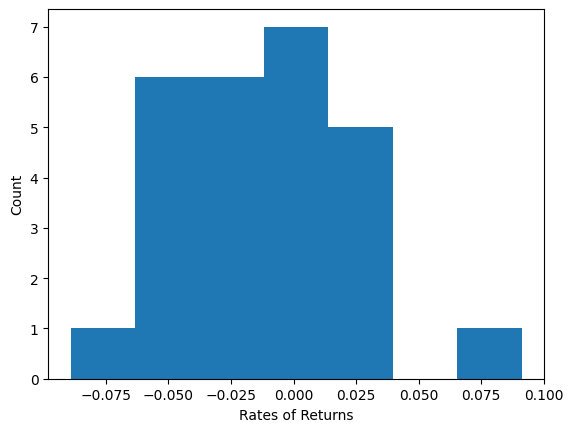

In [103]:
# Create histogram of EUR/CZK Returns
plt.hist(eur_czk["Returns"], bins=7)
plt.xlabel("Rates of Returns")
plt.ylabel("Count")
plt.show
#plt.savefig("EUR_hist.pdf", format="pdf", bbox_inches="tight")



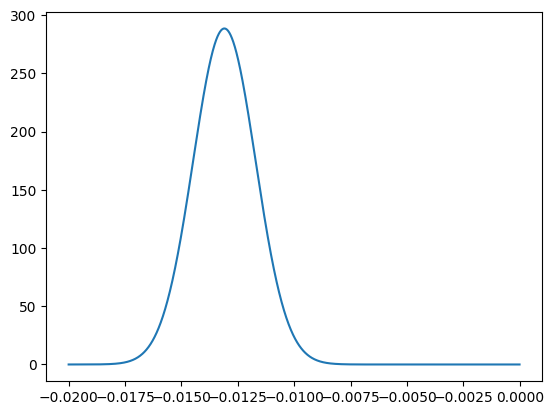

In [130]:
# Plot between -10 and 10 with .001 steps.
x_axis = np.arange(-0.02, 0.00, 0.00001)
#x_axis = np.arange(-0.08, 0.05, 0.00001)
# Mean = 0, SD = 2.
plt.plot(x_axis, norm.pdf(x_axis,EUR_mean,EUR_var))
plt.show()

### **USD/CZK**

In [56]:
# Load in the data
usd_czk = pd.read_excel("data/exchange_rates/USD_CZK.xlsx")

In [ ]:
#usd_czk['Date'] = pd.to_datetime(usd_czk['Date'])
usd_czk[usd_czk['Date'] >= '1993-02-08']

,Date,CZK= (BID),Returns
2,2024-01-01,24.324,0.088225
3,2023-01-02,22.352,-0.008956
4,2022-01-03,22.554,0.032267
5,2021-01-01,21.849,0.018744
6,2020-01-01,21.447,-0.053614
7,2019-01-01,22.662,0.011019
8,2018-01-01,22.415,0.053435
9,2017-01-02,21.278,-0.170384
10,2016-01-01,25.648,0.031656
11,2015-01-01,24.861,0.088867


In [60]:
# Get rid of first row
usd_czk.drop(index=usd_czk.index[0], axis=0, inplace=True)

In [61]:
# Fill the column Returns will yearly returns in percentages
usd_czk["Returns"] = (
    (usd_czk["CZK= (BID)"] - usd_czk["CZK= (BID)"].shift(-1)) / usd_czk["CZK= (BID)"].shift(-1)
)

In [68]:
# Export back to Excel
usd_czk.to_excel("data/exchange_rates/USD_CZK.xlsx")

In [105]:
# Calculate mean and standard deviation of USD/CZK Returns
USD_mean = np.mean(usd_czk["Returns"])
USD_var = np.var(usd_czk["Returns"])
print(f"The Average is {USD_mean} and the variance is {USD_var}")

The Average is 0.0010660087178357455 and the variance is 0.010391955813095115


<function matplotlib.pyplot.show(close=None, block=None)>

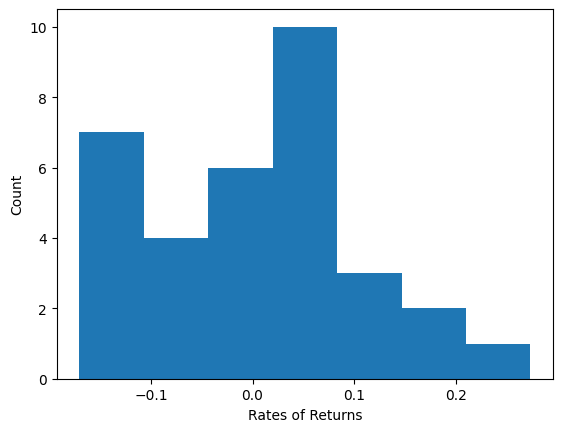

In [104]:
# Create histogram of USD/CZK Returns
plt.hist(usd_czk["Returns"], bins=7)
plt.xlabel("Rates of Returns")
plt.ylabel("Count")
plt.show
#plt.savefig("USD_hist.pdf", format="pdf", bbox_inches="tight")

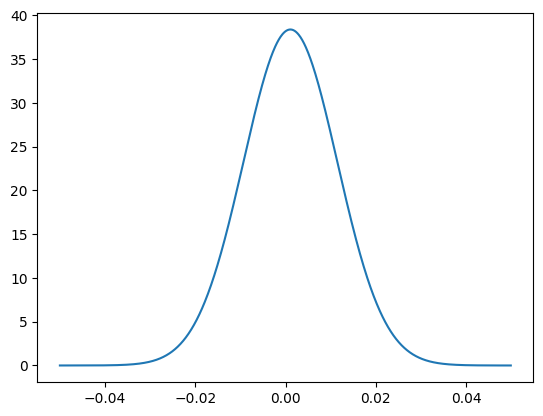

In [109]:
# Plot between -10 and 10 with .001 steps.
x_axis = np.arange(-0.05, 0.05, 0.0001)
# Mean = 0, SD = 2.
plt.plot(x_axis, norm.pdf(x_axis,USD_mean,USD_var))
plt.show()